<a href="https://colab.research.google.com/github/beyza-ozdemir/Face_Recognition_with_CNN_OpenCV./blob/main/Face_Recognition_with_CNN_%26_OpenCV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2 as cv
import tensorflow as tf
from google.colab.patches import cv2_imshow

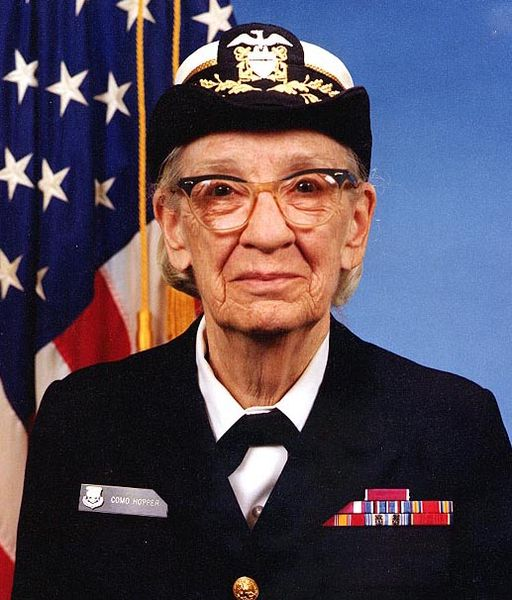

In [2]:
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/grace_hopper.jpg"

image_path = tf.keras.utils.get_file(
    "grace_hopper.jpg",
    origin=url
)

img = cv.imread(image_path)

cv2_imshow(img)

In [3]:
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

haar_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + "haarcascade_frontalface_default.xml"
)

faces = haar_cascade.detectMultiScale(gray)

In [4]:
!pip install opencv-python==4.10.0.84

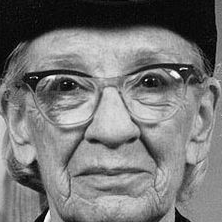

In [5]:
x, y, w, h = faces[0]
face = gray[y:y+h, x:x+w]

cv2_imshow(face)

(1560, 62, 47)
['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Jacques Chirac' 'Jean Chretien'
 'John Ashcroft' 'Junichiro Koizumi' 'Serena Williams' 'Tony Blair']


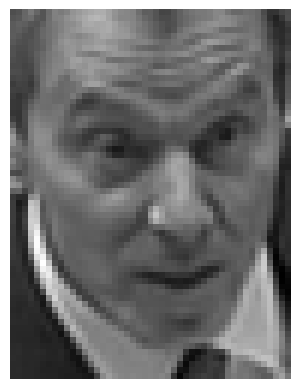

In [6]:
from sklearn.datasets import fetch_lfw_people

lfw = fetch_lfw_people(
    min_faces_per_person=50,
    resize=0.5
)

print(lfw.images.shape)
print(lfw.target_names)

import matplotlib.pyplot as plt

plt.imshow(lfw.images[0], cmap="gray")
plt.axis("off")
plt.show()

In [7]:
X = lfw.images
y = lfw.target

print(X.shape)
print(y.shape)

for i in range(10):
   print(i, lfw.target[i], lfw.target_names[lfw.target[i]])


(1560, 62, 47)
(1560,)
0 11 Tony Blair
1 4 Gerhard Schroeder
2 2 Donald Rumsfeld
3 3 George W Bush
4 3 George W Bush
5 1 Colin Powell
6 0 Ariel Sharon
7 3 George W Bush
8 1 Colin Powell
9 3 George W Bush


In [8]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(X.shape)
print(y.shape)

(1560, 62, 47)
(1560,)


In [9]:
print(X_train.min())
print(X_train.max())


0.0
1.0


In [10]:
import numpy as np
X = X[..., np.newaxis]

In [12]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

model=Sequential([
    Conv2D(32,(3,3),activation="relu",input_shape=(62,47,1)),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation="relu"),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(12, activation="softmax")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 60, 45, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 30, 22, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 20, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8960)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,147,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,167,372 (4.45 MB)

 Trainable params: 1,167,372 (4.45 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]

)

history=model.fit(
    X_train,
    y_train,
    epochs=10,
    validation_data=(X_test, y_test)

)

Epoch 1/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 172ms/step - accuracy: 0.3237 - loss: 2.1837 - val_accuracy: 0.3397 - val_loss: 2.1115
Epoch 2/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 6s 146ms/step - accuracy: 0.3429 - loss: 2.0779 - val_accuracy: 0.3397 - val_loss: 2.0117
Epoch 3/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 17s 305ms/step - accuracy: 0.4014 - loss: 1.8685 - val_accuracy: 0.4519 - val_loss: 1.6913
Epoch 4/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 15s 168ms/step - accuracy: 0.5064 - loss: 1.5291 - val_accuracy: 0.5256 - val_loss: 1.3849
Epoch 5/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 7s 173ms/step - accuracy: 0.6234 - loss: 1.1482 - val_accuracy: 0.7147 - val_loss: 1.0113
Epoch 6/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 9s 150ms/step - accuracy: 0.7404 - loss: 0.8401 - val_accuracy: 0.7532 - val_loss: 0.8335
Epoch 7/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 6s 144ms/step - accuracy: 0.8125 - loss: 0.6141 - val_accuracy: 0.7949 - val_loss: 0.7233
Epoch 8/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 5s 127ms/step - accuracy: 0.8349 - loss: 0.5291 - val_accuracy: 

In [15]:
pred=model.predict(X_test[0:1])
predicted_label=np.argmax(pred)
print(lfw.target_names[predicted_label])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
George W Bush


In [17]:
test_loss,test_acc=model.evaluate(
    X_test,
    y_test
)

print("Test accuracy:", test_acc)
print("Test loss:", test_loss)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8333 - loss: 0.6176
Test accuracy: 0.8333333134651184
Test loss: 0.6176289319992065


In [18]:
pred = model.predict(
    X_test[0:1]
)

predicted_label = np.argmax(pred)

print(
    "Tahmin edilen kişi:",
    lfw.target_names[predicted_label]
)

print(
    "Gerçek kişi:",
    lfw.target_names[y_test[0]]
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Tahmin edilen kişi: George W Bush
Gerçek kişi: George W Bush


Bulunan yüz sayısı: 0
